# Experimenting with EfficientNetB0 with Pretrained Weights

## Load EfficientNetB0 with pretrained weights

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from datasets import load_dataset

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import EfficientNet_B0_Weights

from sklearn.metrics import classification_report, confusion_matrix

In [11]:
import os

PROJECT_DIR = "/kaggle/working/FoodCNN_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## Load Food-101 dataset

In [12]:
dataset = load_dataset("ethz/food101")

train_data = dataset["train"]
val_data = dataset["validation"]

class_names = train_data.features["label"].names

NUM_CLASSES = len(class_names)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)

README.md:   0%|          | 0.00/16.4k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  464MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

... (16 outputs left out)

data/validation-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/75750 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25250 [00:00<?, ? examples/s]

Training images: 75750
Validation images: 25250
Number of classes: 101
Classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobste

Food-101 has 101 categories

## Image Preprocessing and augmentation

- EfficientNetB0 pretrained on ImageNet expects 224 x 224 images and ImageNet normalization
- We'll use data augmentation during training to help the model generalize 

In [14]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [15]:
val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Create the Dataset Class

In [16]:
class FoodDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        item = self.dataset[index]
        image = item["image"].convert("RGB")
        label = item["label"]

        if self.transform:
            image = self.transform(image)

        return image, label

## Create Data Loaders

In [17]:
train_dataset = FoodDataset(
    train_data,
    transform=train_transform
)

val_dataset = FoodDataset(
    val_data,
    transform=val_transform
)

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 2368
Validation batches: 790


## Load EfficientNetB0

In [18]:
weights = EfficientNet_B0_Weights.DEFAULT

In [19]:
model = models.efficientnet_b0(weights=weights)

In [20]:
# Replace the final classification layer
num_features = model.classifier[1].in_features

In [21]:
model.classifier[1] = nn.Linear(num_features, NUM_CLASSES)

In [23]:
model = model.to(device)

print(model)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

## Define Loss function and evaluation metrics

In [24]:
criterion = nn.CrossEntropyLoss()

In [25]:
def train_model(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [26]:
def evaluate_model(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

## Initialize training history

In [27]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

BEST_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_efficientnet_b0.pth"
)

## Stage 1 - Train the Classification Layer

The model already knows how to recognize visual features from ImageNet. We initially train only the new classification layer to recognize the 101 food categories

In [28]:
# Freeze all feature extraction layers
for param in model.features.parameters():
    param.requires_grad = False

# Keep the classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Optimizer only updates trainable parameters
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

STAGE1_EPOCHS = 5

for epoch in range(STAGE1_EPOCHS):

    print(f"\nStage 1 - Epoch {epoch + 1}/{STAGE1_EPOCHS}")

    train_loss, train_acc = train_model(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "best_val_acc": best_val_acc,
            "history": history
        }, BEST_MODEL_PATH)

        print("Best model saved!")


Stage 1 - Epoch 1/5


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 2.9485
Train Accuracy: 32.82%
Validation Loss: 1.8555
Validation Accuracy: 54.97%
Best model saved!

Stage 1 - Epoch 2/5


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 2.5720
Train Accuracy: 39.20%
Validation Loss: 1.7394
Validation Accuracy: 56.65%
Best model saved!

Stage 1 - Epoch 3/5


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 2.5174
Train Accuracy: 40.21%
Validation Loss: 1.6910
Validation Accuracy: 57.54%
Best model saved!

Stage 1 - Epoch 4/5


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 2.4946
Train Accuracy: 40.79%
Validation Loss: 1.6421
Validation Accuracy: 58.10%
Best model saved!

Stage 1 - Epoch 5/5


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 2.4820
Train Accuracy: 41.33%
Validation Loss: 1.6194
Validation Accuracy: 58.71%
Best model saved!


## Stage 2 - Fine-tune the entire model

Now the model can adjust its pretrained features to recognize food-specific characteristics.
We use a much smaller rate to avoid destroying the useful pretrained knowledge

In [29]:
# Unfreeze all layers
for param in model.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

STAGE2_EPOCHS = 15

for epoch in range(STAGE2_EPOCHS):

    print(f"\nStage 2 - Epoch {epoch + 1}/{STAGE2_EPOCHS}")

    train_loss, train_acc = train_model(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": STAGE1_EPOCHS + epoch + 1,
            "best_val_acc": best_val_acc,
            "history": history
        }, BEST_MODEL_PATH)

        print("Best model saved!")

print("\nTraining completed!")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")


Stage 2 - Epoch 1/15


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 1.7833
Train Accuracy: 55.66%
Validation Loss: 0.8202
Validation Accuracy: 77.37%
Best model saved!

Stage 2 - Epoch 2/15


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 1.4357
Train Accuracy: 63.45%
Validation Loss: 0.6982
Validation Accuracy: 80.53%
Best model saved!

Stage 2 - Epoch 3/15


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

... (21 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 0.7671
Train Accuracy: 79.41%
Validation Loss: 0.5074
Validation Accuracy: 86.33%
Best model saved!

Stage 2 - Epoch 15/15


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

Train Loss: 0.7431
Train Accuracy: 79.84%
Validation Loss: 0.5070
Validation Accuracy: 86.33%

Training completed!
Best Validation Accuracy: 86.33%


## Load the Best Model

In [30]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(device)

model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_acc"])

Best epoch: 19
Best validation accuracy: 86.33267326732673


## Plot training & validation performance

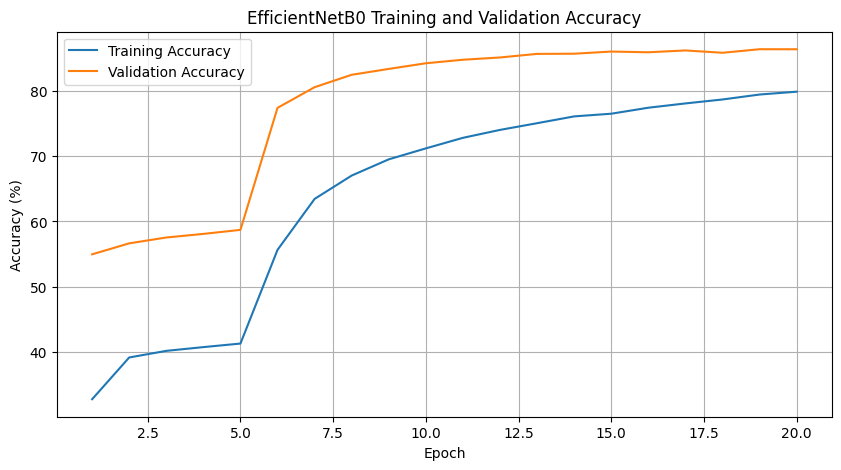

In [31]:
epochs_range = range(1, len(history["train_loss"]) + 1)

# Plot accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("EfficientNetB0 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

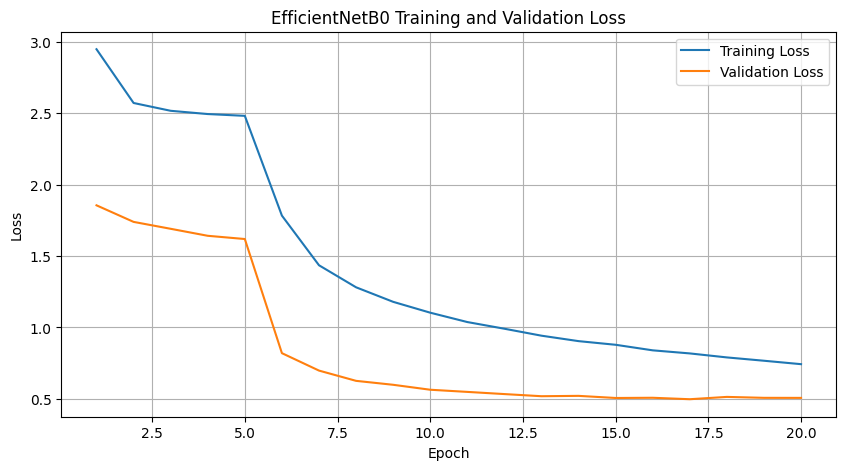

In [32]:
# Plot loss
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB0 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

## Evaluate the Model

In [33]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34855
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 272
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37386
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33437
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 37510
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
/usr/local/lib/python3.13/dist-packag

                         precision    recall  f1-score   support

              apple_pie       0.74      0.65      0.70       250
         baby_back_ribs       0.83      0.88      0.85       250
                baklava       0.92      0.89      0.90       250
         beef_carpaccio       0.95      0.85      0.90       250
           beef_tartare       0.85      0.84      0.84       250
             beet_salad       0.78      0.80      0.79       250
               beignets       0.93      0.84      0.88       250
               bibimbap       0.94      0.95      0.95       250
          bread_pudding       0.72      0.71      0.71       250
      breakfast_burrito       0.83      0.79      0.81       250
             bruschetta       0.82      0.79      0.80       250
           caesar_salad       0.85      0.91      0.88       250
                cannoli       0.89      0.96      0.92       250
          caprese_salad       0.85      0.88      0.86       250
            carrot_cake 

## Save the final model

In [34]:
FINAL_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "efficientnet_b0_food101_final.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": NUM_CLASSES,
    "best_val_acc": best_val_acc
}, FINAL_MODEL_PATH)

print("Final model saved to:", FINAL_MODEL_PATH)

Final model saved to: /kaggle/working/FoodCNN_Project/efficientnet_b0_food101_final.pth


## Test working of model with some images (source online)

In [50]:
from PIL import Image

def predict_food(image_path):
    # Load image
    image = Image.open(image_path).convert("RGB")

    # Prepocess image
    image_tensor = val_transform(image)

    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Make prediction
    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        top_probs, top_indices = torch.topk(
            probabilities,
            k = 5,
            dim = 1
        )

    top_probs = top_probs.cpu().numpy()[0]
    top_indices = top_indices.cpu().numpy()[0]

    # Display image
    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Food Image")
    plt.show()

    # Display predictions
    print("Top 5 predictions:\n")

    for i in range(5):
        food_name = class_names[top_indices[i]]
        confidence = top_probs[i] * 100

        print(f"{i + 1}. {food_name}: {confidence:.2f}%")

    print("\nPredicted food:", class_names[top_indices[0]])

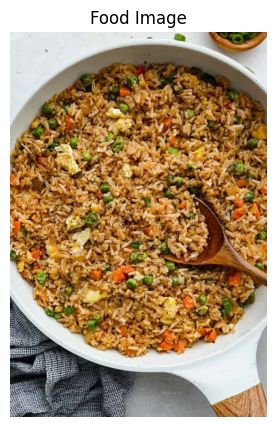

Top 5 predictions:

1. fried_rice: 98.89%
2. paella: 0.83%
3. bibimbap: 0.21%
4. spaghetti_bolognese: 0.02%
5. pizza: 0.01%

Predicted food: fried_rice
Actual food:  fried_rice



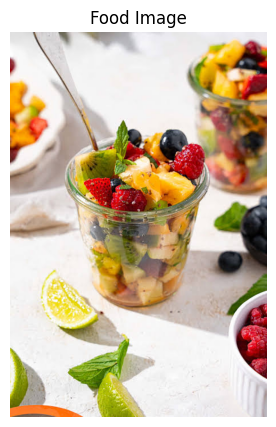

Top 5 predictions:

1. frozen_yogurt: 54.43%
2. ceviche: 16.57%
3. greek_salad: 15.32%
4. tuna_tartare: 4.20%
5. chocolate_mousse: 2.53%

Predicted food: frozen_yogurt
Actual food:  fruit_salad



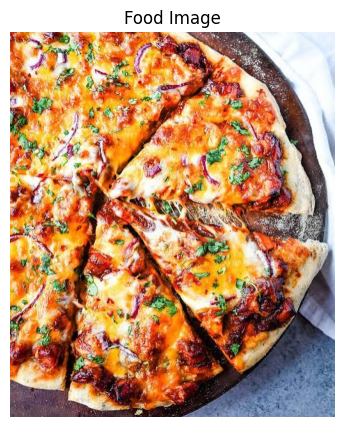

Top 5 predictions:

1. pizza: 92.03%
2. garlic_bread: 2.81%
3. lasagna: 2.49%
4. bruschetta: 1.21%
5. ravioli: 0.84%

Predicted food: pizza
Actual food:  pizza



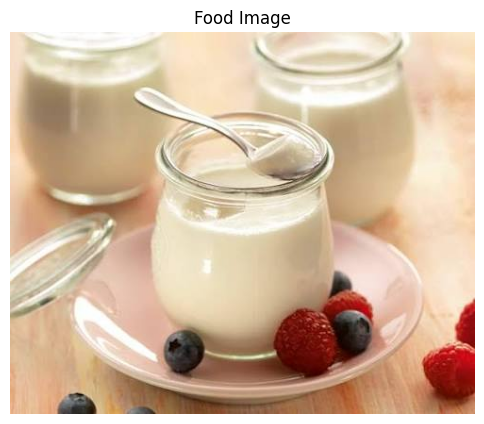

Top 5 predictions:

1. panna_cotta: 72.62%
2. tiramisu: 12.69%
3. chocolate_mousse: 6.08%
4. strawberry_shortcake: 2.01%
5. bread_pudding: 1.09%

Predicted food: panna_cotta
Actual food:  plain_yoghurt



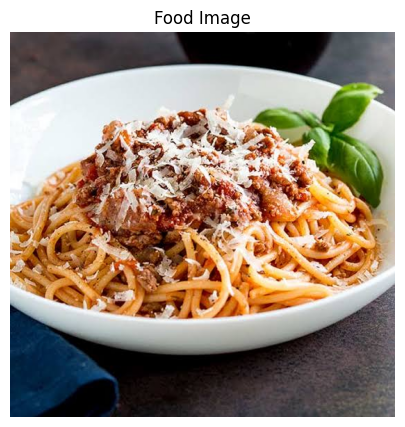

Top 5 predictions:

1. spaghetti_bolognese: 99.84%
2. spaghetti_carbonara: 0.16%
3. pad_thai: 0.00%
4. grilled_salmon: 0.00%
5. bibimbap: 0.00%

Predicted food: spaghetti_bolognese
Actual food:  spaghetti_bolognese



In [54]:
test_foods = [
    "fried_rice",
    "fruit_salad",
    "pizza",
    "plain_yoghurt",
    "spaghetti_bolognese"
]

for food in test_foods:
    image_path = f"/kaggle/input/datasets/wendywendoochieng/test-foods/{food}.jpg"

    predict_food(image_path)
    print("Actual food: ", food)

    print()

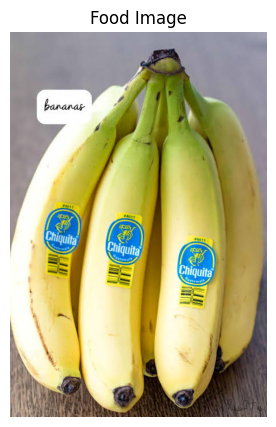

Top 5 predictions:

1. hot_dog: 41.01%
2. ice_cream: 13.12%
3. peking_duck: 10.64%
4. spring_rolls: 4.29%
5. macarons: 3.45%

Predicted food: hot_dog
Actual food:  bananas



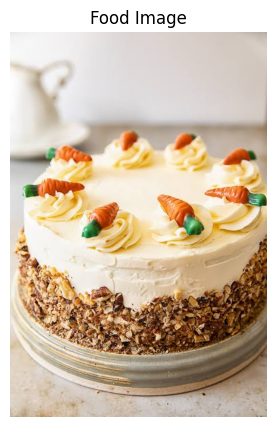

Top 5 predictions:

1. carrot_cake: 99.99%
2. red_velvet_cake: 0.01%
3. strawberry_shortcake: 0.00%
4. cup_cakes: 0.00%
5. cheesecake: 0.00%

Predicted food: carrot_cake
Actual food:  carrot_cake



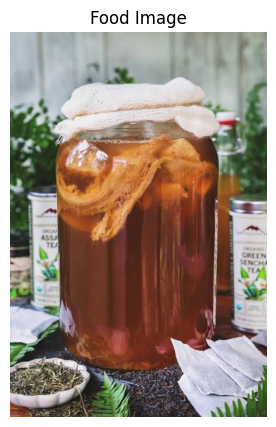

Top 5 predictions:

1. churros: 32.11%
2. cup_cakes: 10.82%
3. poutine: 6.46%
4. waffles: 4.02%
5. ice_cream: 3.20%

Predicted food: churros
Actual food:  kombucha



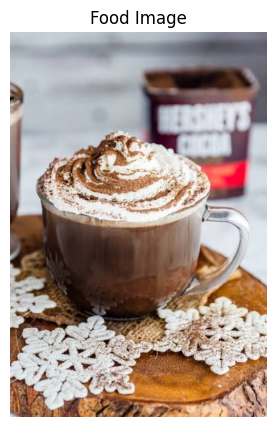

Top 5 predictions:

1. chocolate_mousse: 94.22%
2. tiramisu: 3.60%
3. chocolate_cake: 1.03%
4. churros: 0.31%
5. panna_cotta: 0.27%

Predicted food: chocolate_mousse
Actual food:  mocha



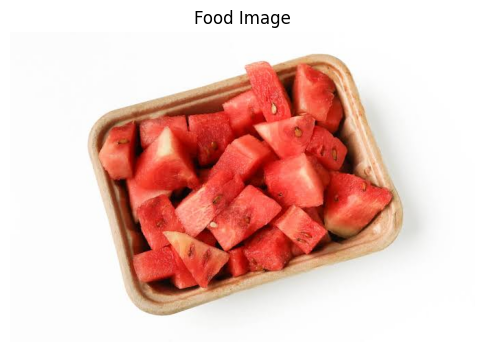

Top 5 predictions:

1. waffles: 26.02%
2. baklava: 10.21%
3. breakfast_burrito: 8.61%
4. sashimi: 7.52%
5. peking_duck: 5.87%

Predicted food: waffles
Actual food:  watermelon



In [55]:
test_foods = [
    "bananas",
    "carrot_cake",
    "kombucha",
    "mocha",
    "watermelon"
]

for food in test_foods:
    image_path = f"/kaggle/input/datasets/wendywendoochieng/test-foods2/{food}.jpg"

    predict_food(image_path)
    print("Actual food: ", food)

    print()